<a href="https://colab.research.google.com/github/stjsmith8/ADS_599_Capstone_Project/blob/main/03_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ADS-599 Capstone

03 Modeling

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from pathlib import Path

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.stats import spearmanr
from xgboost import XGBRegressor
from sklearn.base import clone

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

Load data.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

OUTPUT = Path('/content/drive/MyDrive/Cell_Painting_Capstone/outputs')

model_train = pd.read_csv(
    OUTPUT / "model_train.csv",
    index_col=0
)

model_test = pd.read_csv(
    OUTPUT / "model_test.csv",
    index_col=0
)

print("Training dataset:", model_train.shape)
print("Test dataset:", model_test.shape)

display(model_train.head())

Mounted at /content/drive
Training dataset: (1949, 5)
Test dataset: (488, 5)


,Mean_Object_Count,Min_Object_Count,Object_Count_Difference,Morphological_Disagreement,Improvement
Metadata_EOS,,,,,
EOS101892,723.0,575,296,35.428768,1.031428
EOS101010,788.5,668,241,35.661397,-1.084510
EOS101568,611.0,447,328,31.808877,-1.742034
EOS100301,945.5,699,493,41.304457,0.545278
EOS101741,832.0,677,310,28.595679,3.020506


Define predictors and outcome

In [6]:
predictors = [
    "Mean_Object_Count",
    "Min_Object_Count",
    "Object_Count_Difference",
    "Morphological_Disagreement"
]

target = "Improvement"

X_train = model_train[predictors].copy()
y_train = model_train[target].copy()

print("Predictors:", predictors)
print("Training observations:", len(X_train))

assert X_train.notna().all().all()
assert y_train.notna().all()
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(y_train.to_numpy()).all()

Predictors: ['Mean_Object_Count', 'Min_Object_Count', 'Object_Count_Difference', 'Morphological_Disagreement']
Training observations: 1949


Define the models.

In [7]:
models = {
    "Dummy": DummyRegressor(
        strategy="mean"
    ),

    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=1
    )
}

In [8]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

results = []
oof_predictions = pd.DataFrame(index=X_train.index)

for name, model in models.items():

    predictions = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        n_jobs=1
    )

    oof_predictions[name] = predictions

    mae = mean_absolute_error(y_train, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_train, predictions)
    )

    r2 = r2_score(y_train, predictions)

    rho, _ = spearmanr(y_train, predictions)

    results.append({
        "Model": name,
        "CV_MAE": mae,
        "CV_RMSE": rmse,
        "CV_R2": r2,
        "CV_Spearman": rho
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("CV_MAE")
    .reset_index(drop=True)
)

display(results_df.round(4))

,Model,CV_MAE,CV_RMSE,CV_R2,CV_Spearman
0,XGBoost,2.3841,3.2732,0.1495,0.1465
1,Dummy,2.4191,3.5505,-0.0008,-0.0510
2,Random Forest,2.4526,3.3783,0.0940,0.1132
3,Ridge,2.4750,3.4115,0.0761,-0.0676


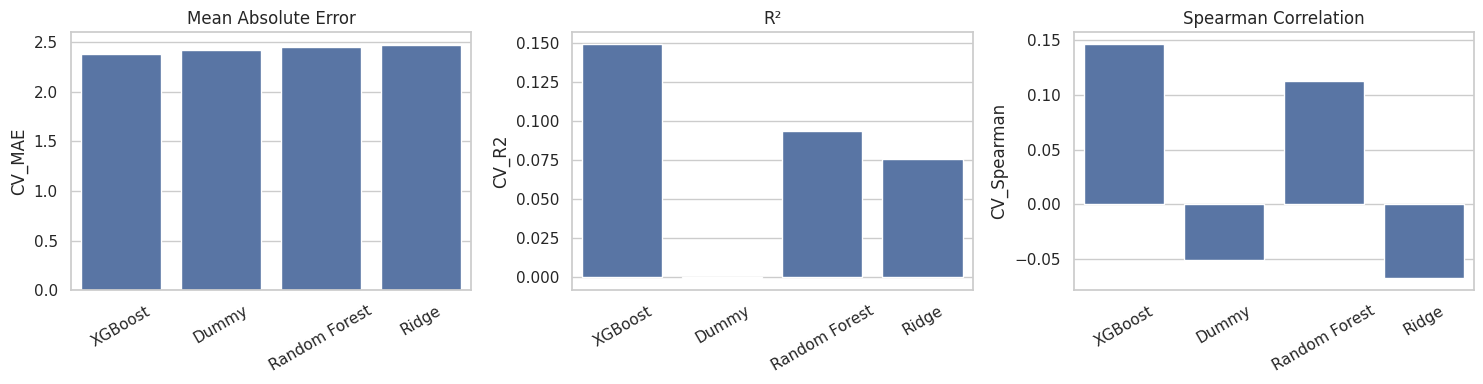

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("CV_MAE", "Mean Absolute Error"),
    ("CV_R2", "R²"),
    ("CV_Spearman", "Spearman Correlation")
]

for ax, (metric, title) in zip(axes, metrics):

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Compare predicted improvement vs actual improvement

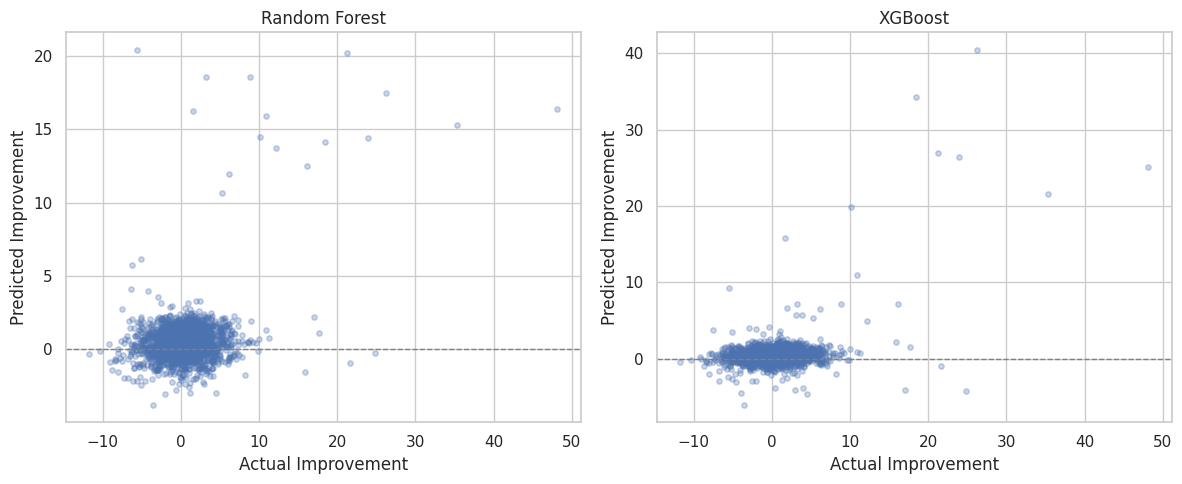

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(
    axes,
    ["Random Forest", "XGBoost"]
):

    ax.scatter(
        y_train,
        oof_predictions[name],
        alpha=0.3,
        s=15
    )

    ax.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Improvement")
    ax.set_ylabel("Predicted Improvement")

plt.tight_layout()
plt.show()

Evaluate against other replicate allocation strategies.

In [11]:
budgets = [0.10, 0.20, 0.30]

allocation_scores = {
    "Random": None,
    "Highest Disagreement": X_train[
        "Morphological_Disagreement"
    ],
    "Lowest Object Count": -X_train[
        "Min_Object_Count"
    ],
    "Ridge": oof_predictions["Ridge"],
    "Random Forest": oof_predictions["Random Forest"],
    "XGBoost": oof_predictions["XGBoost"]
}

rng = np.random.default_rng(RANDOM_STATE)

allocation_results = []

for budget in budgets:

    n_selected = int(
        np.ceil(len(X_train) * budget)
    )

    for strategy, scores in allocation_scores.items():

        if strategy == "Random":

            random_means = []

            for _ in range(1000):

                selected = rng.choice(
                    len(y_train),
                    size=n_selected,
                    replace=False
                )

                random_means.append(
                    y_train.iloc[selected].mean()
                )

            mean_improvement = np.mean(random_means)

            pct_improved = np.mean([
                (y_train.iloc[
                    rng.choice(
                        len(y_train),
                        size=n_selected,
                        replace=False
                    )
                ] > 0).mean() * 100
                for _ in range(1000)
            ])

        else:

            selected_ids = (
                scores
                .sort_values(ascending=False)
                .head(n_selected)
                .index
            )

            selected_outcomes = y_train.loc[
                selected_ids
            ]

            mean_improvement = selected_outcomes.mean()

            pct_improved = (
                (selected_outcomes > 0).mean() * 100
            )

        allocation_results.append({
            "Budget": f"{int(budget * 100)}%",
            "Strategy": strategy,
            "N_Selected": n_selected,
            "Mean_Improvement": mean_improvement,
            "Pct_Improved": pct_improved
        })

allocation_df = pd.DataFrame(allocation_results)

display(
    allocation_df.round(3)
)

,Budget,Strategy,N_Selected,Mean_Improvement,Pct_Improved
0,10%,Random,195,0.566,59.139
1,10%,Highest Disagreement,195,1.595,54.359
2,10%,Lowest Object Count,195,1.990,62.051
3,10%,Ridge,195,1.610,54.359
4,10%,Random Forest,195,1.765,63.590
5,10%,XGBoost,195,2.263,69.231
6,20%,Random,390,0.559,59.148
7,20%,Highest Disagreement,390,0.905,54.359
8,20%,Lowest Object Count,390,1.467,62.051
9,20%,Ridge,390,0.827,53.077


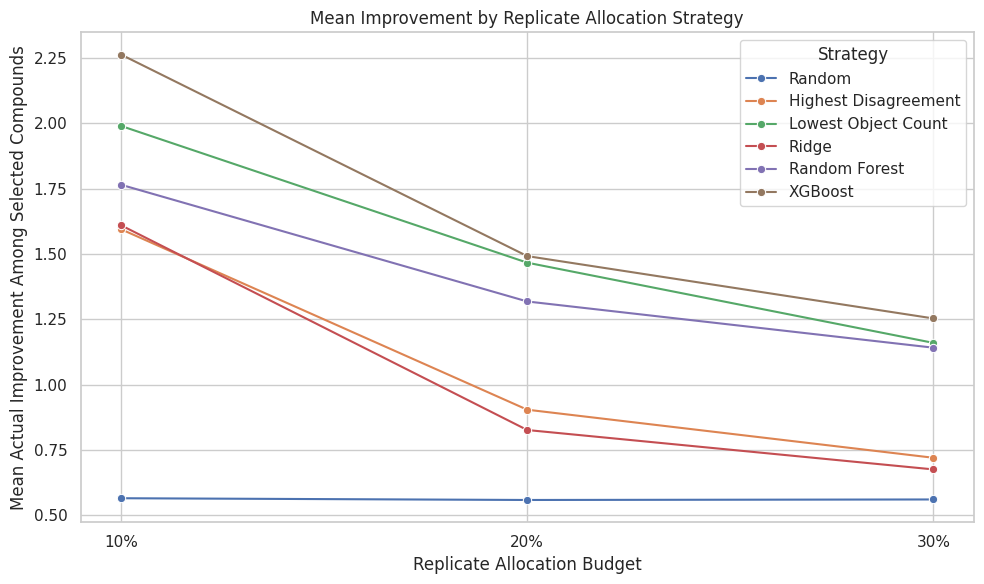

In [12]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=allocation_df,
    x="Budget",
    y="Mean_Improvement",
    hue="Strategy",
    marker="o"
)

plt.title("Mean Improvement by Replicate Allocation Strategy")
plt.xlabel("Replicate Allocation Budget")
plt.ylabel("Mean Actual Improvement Among Selected Compounds")

plt.tight_layout()
plt.show()

Examine feature importance.

In [13]:
importance_results = []

for name in ["Random Forest", "XGBoost"]:

    model = models[name]
    model.fit(X_train, y_train)

    for feature, importance in zip(
        predictors,
        model.feature_importances_
    ):

        importance_results.append({
            "Model": name,
            "Feature": feature,
            "Importance": importance
        })

importance_df = pd.DataFrame(importance_results)

display(importance_df.round(4))

,Model,Feature,Importance
0,Random Forest,Mean_Object_Count,0.1626
1,Random Forest,Min_Object_Count,0.1762
2,Random Forest,Object_Count_Difference,0.1726
3,Random Forest,Morphological_Disagreement,0.4887
4,XGBoost,Mean_Object_Count,0.1779
5,XGBoost,Min_Object_Count,0.1604
6,XGBoost,Object_Count_Difference,0.1925
7,XGBoost,Morphological_Disagreement,0.4691


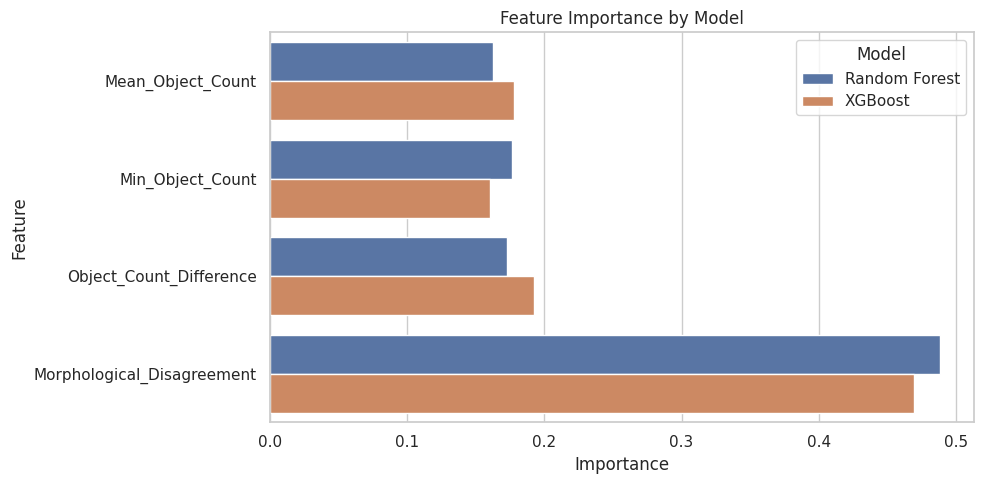

In [14]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Model"
)

plt.title("Feature Importance by Model")
plt.tight_layout()
plt.show()

Save results

In [15]:
results_df.to_csv(
    OUTPUT / "model_comparison.csv",
    index=False
)

allocation_df.to_csv(
    OUTPUT / "allocation_comparison.csv",
    index=False
)

oof_predictions.to_csv(
    OUTPUT / "oof_predictions.csv"
)

importance_df.to_csv(
    OUTPUT / "feature_importance.csv",
    index=False
)

print("Notebook 03 results saved.")

Notebook 03 results saved.


In [18]:
# Examine extreme XGBoost predictions
extreme_predictions = pd.DataFrame({
    "Actual_Improvement": y_train,
    "Predicted_Improvement": oof_predictions["XGBoost"],
    "Morphological_Disagreement": X_train["Morphological_Disagreement"],
    "Min_Object_Count": X_train["Min_Object_Count"],
    "Mean_Object_Count": X_train["Mean_Object_Count"],
    "Object_Count_Difference": X_train["Object_Count_Difference"]
})

# Sort by highest predicted improvement
extreme_predictions = extreme_predictions.sort_values(
    "Predicted_Improvement",
    ascending=False
)

display(extreme_predictions.head(15))

,Actual_Improvement,Predicted_Improvement,Morphological_Disagreement,Min_Object_Count,Mean_Object_Count,Object_Count_Difference
Metadata_EOS,,,,,,
EOS100013,26.249675,40.408485,287.711398,4,448.0,888
EOS100012,18.382697,34.308960,249.584184,1,288.5,575
EOS100966,21.247322,26.864590,309.288071,1,14.5,27
EOS100442,23.941067,26.373676,284.818884,1,7.0,12
EOS101406,48.174716,25.095057,311.741071,4,325.5,643
EOS100060,35.295188,21.535820,351.590202,1,5.5,9
EOS101119,10.103733,19.857038,202.778967,5,9.5,9
EOS100679,1.604603,15.739112,181.960323,4,9.0,10
EOS100555,10.880682,10.994859,222.573691,2,4.0,4


In [19]:
# Create object-count categories
analysis_df = extreme_predictions.copy()

analysis_df["Object_Count_Group"] = pd.cut(
    analysis_df["Min_Object_Count"],
    bins=[-1, 5, 20, 100, np.inf],
    labels=["0–5", "6–20", "21–100", ">100"]
)

# Summarize actual improvement by object-count group
summary = (
    analysis_df
    .groupby("Object_Count_Group", observed=True)
    .agg(
        N_Compounds=("Actual_Improvement", "count"),
        Mean_Actual_Improvement=("Actual_Improvement", "mean"),
        Median_Actual_Improvement=("Actual_Improvement", "median"),
        Mean_Predicted_Improvement=("Predicted_Improvement", "mean")
    )
)

display(summary.round(3))

,N_Compounds,Mean_Actual_Improvement,Median_Actual_Improvement,Mean_Predicted_Improvement
Object_Count_Group,,,,
0–5,15,15.787,12.140,17.555
6–20,5,0.819,0.443,1.017
21–100,20,2.404,0.656,1.024
>100,1909,0.424,0.608,0.413


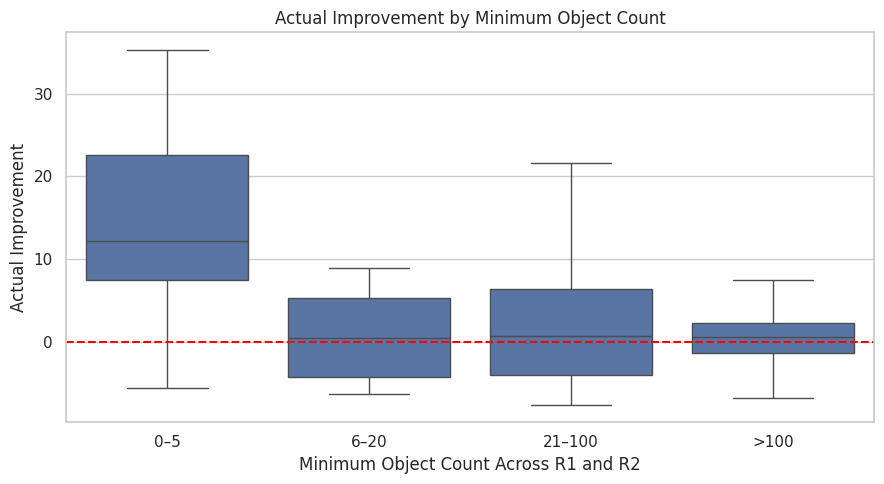

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=analysis_df,
    x="Object_Count_Group",
    y="Actual_Improvement",
    showfliers=False
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Actual Improvement by Minimum Object Count")
plt.xlabel("Minimum Object Count Across R1 and R2")
plt.ylabel("Actual Improvement")

plt.tight_layout()
plt.show()

Sensitivty analysis

In [22]:
# Use minimum object counts from the training dataset
minimum_counts = model_train["Min_Object_Count"]

# Define sensitivity analysis scenarios
scenarios = {
    "All compounds": minimum_counts.index.tolist(),

    "Min count > 5": minimum_counts[
        minimum_counts > 5
    ].index.tolist(),

    "Min count > 20": minimum_counts[
        minimum_counts > 20
    ].index.tolist()
}

# Display sample sizes
for name, ids in scenarios.items():
    print(f"{name}: {len(ids)} compounds")

All compounds: 1949 compounds
Min count > 5: 1934 compounds
Min count > 20: 1929 compounds


In [24]:
sensitivity_results = []
sensitivity_predictions = []

for scenario_name, ids in scenarios.items():

    X = X_train.loc[ids]
    y = y_train.loc[ids]

    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    for model_name in ["Random Forest", "XGBoost"]:

        model = clone(models[model_name])

        predictions = cross_val_predict(
            model,
            X,
            y,
            cv=cv,
            n_jobs=1
        )

        rho, _ = spearmanr(y, predictions)

        sensitivity_results.append({
            "Scenario": scenario_name,
            "Model": model_name,
            "N_Compounds": len(X),
            "CV_MAE": mean_absolute_error(y, predictions),
            "CV_R2": r2_score(y, predictions),
            "CV_Spearman": rho
        })

        for compound_id, actual, predicted in zip(
            X.index, y, predictions
        ):

            sensitivity_predictions.append({
                "Scenario": scenario_name,
                "Model": model_name,
                "Metadata_EOS": compound_id,
                "Actual_Improvement": actual,
                "Predicted_Improvement": predicted,
                "Min_Object_Count": X.loc[
                    compound_id, "Min_Object_Count"
                ]
            })

sensitivity_results_df = pd.DataFrame(sensitivity_results)
sensitivity_predictions_df = pd.DataFrame(sensitivity_predictions)

display(sensitivity_results_df.round(4))

,Scenario,Model,N_Compounds,CV_MAE,CV_R2,CV_Spearman
0,All compounds,Random Forest,1949,2.4526,0.0940,0.1132
1,All compounds,XGBoost,1949,2.3841,0.1495,0.1465
2,Min count > 5,Random Forest,1934,2.3741,-0.0563,0.0983
3,Min count > 5,XGBoost,1934,2.3498,-0.0433,0.1110
4,Min count > 20,Random Forest,1929,2.3875,-0.0799,0.0831
5,Min count > 20,XGBoost,1929,2.3795,-0.1249,0.0827


In [25]:
budgets = [0.10, 0.20, 0.30]

allocation_results = []

for (scenario, model_name), group in (
    sensitivity_predictions_df
    .groupby(["Scenario", "Model"])
):

    for budget in budgets:

        n_selected = int(np.ceil(len(group) * budget))

        strategies = {
            model_name: group["Predicted_Improvement"],
            "Lowest Object Count": -group["Min_Object_Count"]
        }

        for strategy, scores in strategies.items():

            selected = group.loc[
                scores.nlargest(n_selected).index
            ]

            allocation_results.append({
                "Scenario": scenario,
                "Model": model_name,
                "Budget": int(budget * 100),
                "Strategy": strategy,
                "Mean_Improvement": selected[
                    "Actual_Improvement"
                ].mean(),
                "Pct_Improved": (
                    selected["Actual_Improvement"] > 0
                ).mean() * 100
            })

sensitivity_allocation_df = pd.DataFrame(allocation_results)

display(sensitivity_allocation_df.round(3))

,Scenario,Model,Budget,Strategy,Mean_Improvement,Pct_Improved
0,All compounds,Random Forest,10,Random Forest,1.765,63.590
1,All compounds,Random Forest,10,Lowest Object Count,1.990,62.051
2,All compounds,Random Forest,20,Random Forest,1.319,62.308
3,All compounds,Random Forest,20,Lowest Object Count,1.467,62.051
4,All compounds,Random Forest,30,Random Forest,1.142,62.393
5,All compounds,Random Forest,30,Lowest Object Count,1.160,61.368
6,All compounds,XGBoost,10,XGBoost,2.263,69.231
7,All compounds,XGBoost,10,Lowest Object Count,1.990,62.051
8,All compounds,XGBoost,20,XGBoost,1.492,65.385
9,All compounds,XGBoost,20,Lowest Object Count,1.467,62.051


In [26]:
comparison = (
    sensitivity_allocation_df
    .pivot_table(
        index=["Scenario", "Model", "Budget"],
        columns="Strategy",
        values="Mean_Improvement"
    )
    .reset_index()
)

comparison["Advantage_Over_Heuristic"] = np.where(
    comparison["Model"] == "XGBoost",
    comparison["XGBoost"] - comparison["Lowest Object Count"],
    comparison["Random Forest"] - comparison["Lowest Object Count"]
)

display(
    comparison[
        [
            "Scenario",
            "Model",
            "Budget",
            "Advantage_Over_Heuristic"
        ]
    ].round(3)
)

Strategy,Scenario,Model,Budget,Advantage_Over_Heuristic
0,All compounds,Random Forest,10,-0.225
1,All compounds,Random Forest,20,-0.148
2,All compounds,Random Forest,30,-0.018
3,All compounds,XGBoost,10,0.273
4,All compounds,XGBoost,20,0.025
5,All compounds,XGBoost,30,0.093
6,Min count > 20,Random Forest,10,-0.346
7,Min count > 20,Random Forest,20,-0.225
8,Min count > 20,Random Forest,30,-0.130
9,Min count > 20,XGBoost,10,-0.121
